# 05 - Model Building

Predict which customers will churn. Steps: preprocessing pipeline, compare four models with cross-validation, tune the best candidates, choose a decision threshold, then evaluate once on the held-out test set.

The test set (20%) is not touched until the final evaluation.

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, confusion_matrix, roc_curve, precision_recall_curve,
                             precision_recall_fscore_support)

sns.set_theme(style="whitegrid", palette="deep")
SEED = 42
IMG = "../images/"

df = pd.read_csv("../Data/Processed/churn_features.csv")
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

drop = ["customer_id", "churn_value", "split"]
X_train, y_train = train.drop(columns=drop), train["churn_value"]
X_test, y_test = test.drop(columns=drop), test["churn_value"]
print("train:", X_train.shape, " test:", X_test.shape)
print("churn rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

train: (5634, 32)  test: (1409, 32)
churn rate  train: 0.265  test: 0.265


## Preprocessing

In [2]:
numeric = ["tenure_months", "monthly_charges", "total_charges", "avg_monthly_spend", "charge_vs_avg",
           "num_addons", "num_protection_addons"]
categorical = [c for c in X_train.columns if X_train[c].dtype.kind not in "iufb"]
flags = [c for c in X_train.columns if c not in numeric + categorical]

print("numeric    :", len(numeric))
print("categorical:", len(categorical))
print("binary flag:", len(flags))

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("flag", "passthrough", flags),
])

numeric    : 7
categorical: 16
binary flag: 9


## Baseline comparison (5-fold stratified CV on the training set)

Class imbalance is handled with class weights where the model supports it.

In [3]:
candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                            random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["roc_auc", "average_precision", "recall", "precision", "f1", "accuracy"]

rows = []
for name, model in candidates.items():
    res = cross_validate(Pipeline([("prep", preprocess), ("model", model)]), X_train, y_train,
                         cv=cv, scoring=scoring, n_jobs=-1)
    row = {"model": name}
    row.update({m: res["test_" + m].mean() for m in scoring})
    rows.append(row)

baseline = pd.DataFrame(rows).set_index("model").round(3)
baseline

,roc_auc,average_precision,recall,precision,f1,accuracy
model,,,,,,
Logistic Regression,0.861,0.684,0.813,0.534,0.644,0.762
Random Forest,0.859,0.676,0.731,0.578,0.645,0.787
Gradient Boosting,0.860,0.678,0.552,0.660,0.601,0.806
Hist Gradient Boosting,0.852,0.665,0.740,0.557,0.635,0.775


All four land at about 0.85-0.86 ROC-AUC, which is typical for this dataset. Logistic regression is as good as the tree ensembles and catches the most churners (recall) at default settings; it is also the easiest to explain. Gradient boosting has the best precision but misses many churners at a 0.5 threshold.

The next step tunes logistic regression and gradient boosting, the two most promising and most different candidates.

## Hyperparameter tuning

In [4]:
lr_pipe = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))])
lr_grid = {"model__C": [0.01, 0.05, 0.1, 0.3, 0.5, 1, 3], "model__penalty": ["l1", "l2"], "model__solver": ["liblinear"]}
lr_search = GridSearchCV(lr_pipe, lr_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
print("Logistic Regression best:", lr_search.best_params_)
print("CV ROC-AUC: %.4f" % lr_search.best_score_)

Logistic Regression best: {'model__C': 3, 'model__penalty': 'l2', 'model__solver': 'liblinear'}
CV ROC-AUC: 0.8608


In [5]:
gb_pipe = Pipeline([("prep", preprocess), ("model", GradientBoostingClassifier(random_state=SEED))])
gb_grid = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_leaf": [10, 20, 40],
    "model__subsample": [0.7, 0.85, 1.0],
}
gb_search = RandomizedSearchCV(gb_pipe, gb_grid, n_iter=12, scoring="roc_auc", cv=cv, n_jobs=-1, random_state=SEED)
gb_search.fit(X_train, y_train)
print("Gradient Boosting best:", gb_search.best_params_)
print("CV ROC-AUC: %.4f" % gb_search.best_score_)

Gradient Boosting best: {'model__subsample': 0.85, 'model__n_estimators': 150, 'model__min_samples_leaf': 20, 'model__max_depth': 2, 'model__learning_rate': 0.1}
CV ROC-AUC: 0.8620


In [6]:
tuned = pd.DataFrame({
    "cv_roc_auc": [lr_search.best_score_, gb_search.best_score_],
}, index=["Logistic Regression (tuned)", "Gradient Boosting (tuned)"]).round(4)
tuned

,cv_roc_auc
Logistic Regression (tuned),0.8608
Gradient Boosting (tuned),0.8620


## Model choice

Performance is almost identical, so the choice comes down to the tie-breakers: the logistic regression is simpler, faster to score, and its coefficients can be read directly by the retention team. The better of the two by cross-validated ROC-AUC is selected below, with a preference for logistic regression when the gap is under 0.005.

In [7]:
gap = gb_search.best_score_ - lr_search.best_score_
if gap > 0.005:
    final_name, final_model = "Gradient Boosting", gb_search.best_estimator_
else:
    final_name, final_model = "Logistic Regression", lr_search.best_estimator_
print("Selected model:", final_name, "(AUC gap in favour of boosting: %.4f)" % gap)

Selected model: Logistic Regression (AUC gap in favour of boosting: 0.0012)


## Decision threshold

Missing a churner is costlier than offering a retention deal to someone who would have stayed. The threshold is therefore chosen on out-of-fold predictions from the training set (not the test set) by maximising F2, which weights recall twice as heavily as precision.

In [8]:
oof_proba = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.20, 0.81, 0.01)
def fbeta(p, r, beta=2):
    return (1 + beta**2) * p * r / (beta**2 * p + r) if (p + r) else 0

scores = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    p, r = precision_score(y_train, pred), recall_score(y_train, pred)
    scores.append({"threshold": round(t, 2), "precision": p, "recall": r, "f1": f1_score(y_train, pred), "f2": fbeta(p, r)})
scores = pd.DataFrame(scores)
best = scores.loc[scores["f2"].idxmax()]
THRESHOLD = float(best["threshold"])
print("Chosen threshold:", THRESHOLD)
best.round(3)

Chosen threshold: 0.33


threshold    0.330
precision    0.460
recall       0.907
f1           0.610
f2           0.759

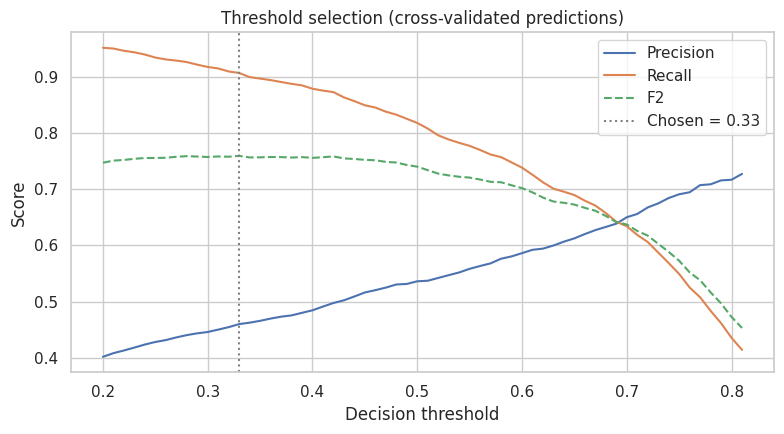

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(scores["threshold"], scores["precision"], label="Precision")
ax.plot(scores["threshold"], scores["recall"], label="Recall")
ax.plot(scores["threshold"], scores["f2"], label="F2", linestyle="--")
ax.axvline(THRESHOLD, color="grey", linestyle=":", label=f"Chosen = {THRESHOLD:.2f}")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold selection (cross-validated predictions)")
ax.legend()
plt.tight_layout()
plt.savefig(IMG + "11_threshold_selection.png", dpi=130, bbox_inches="tight")

## Final evaluation on the test set

In [10]:
final_model.fit(X_train, y_train)
proba = final_model.predict_proba(X_test)[:, 1]

def report(y_true, p, thr):
    pred = (p >= thr).astype(int)
    return {
        "threshold": thr,
        "roc_auc": roc_auc_score(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
    }

results = pd.DataFrame({"default 0.50": report(y_test, proba, 0.5),
                        "tuned threshold": report(y_test, proba, THRESHOLD)}).round(3)
results

,default 0.50,tuned threshold
threshold,0.500,0.330
roc_auc,0.851,0.851
pr_auc,0.641,0.641
accuracy,0.746,0.690
precision,0.514,0.458
recall,0.802,0.914
f1,0.626,0.610


[[630 405]
 [ 32 342]]


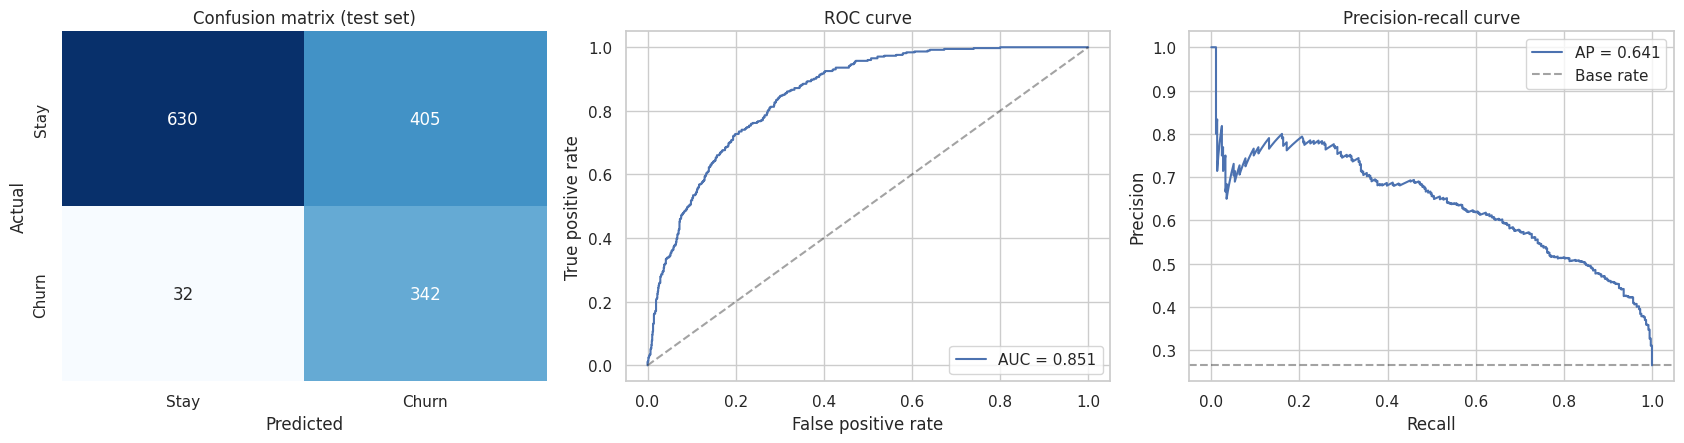

In [11]:
pred = (proba >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[0].set_title("Confusion matrix (test set)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_test, proba)
axes[2].plot(rec, prec, label=f"AP = {average_precision_score(y_test, proba):.3f}")
axes[2].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="Base rate")
axes[2].set_title("Precision-recall curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()

plt.tight_layout()
plt.savefig(IMG + "12_model_evaluation.png", dpi=130, bbox_inches="tight")
print(cm)

In [12]:
tn, fp, fn, tp = cm.ravel()
print(f"Churners caught        : {tp} of {tp + fn} ({tp / (tp + fn):.1%})")
print(f"Churners missed        : {fn}")
print(f"Loyal customers flagged: {fp} of {fp + tn} ({fp / (fp + tn):.1%})")

Churners caught        : 342 of 374 (91.4%)
Churners missed        : 32
Loyal customers flagged: 405 of 1035 (39.1%)


## Model comparison on the test set

,roc_auc,pr_auc
model,,
Logistic Regression (default),0.8515,0.6423
Random Forest (default),0.8522,0.6634
Gradient Boosting (default),0.8529,0.6636
Hist Gradient Boosting (default),0.8480,0.6537
"Logistic Regression (tuned, selected)",0.8511,0.6409


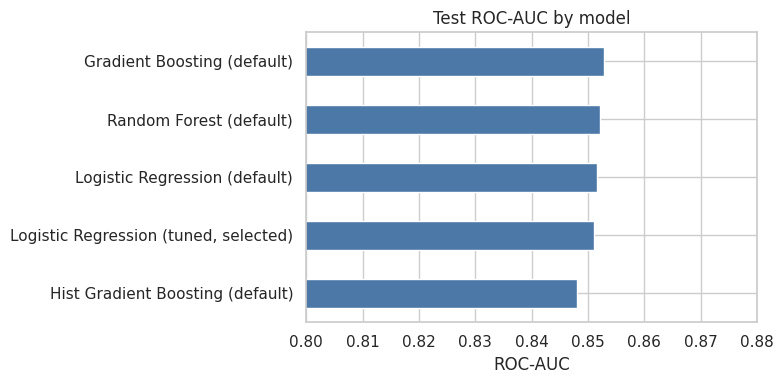

In [13]:
comparison = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)]).fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    comparison.append({"model": name + " (default)", "roc_auc": roc_auc_score(y_test, p),
                       "pr_auc": average_precision_score(y_test, p)})
comparison.append({"model": final_name + " (tuned, selected)", "roc_auc": roc_auc_score(y_test, proba),
                   "pr_auc": average_precision_score(y_test, proba)})
comparison = pd.DataFrame(comparison).set_index("model").round(4)

fig, ax = plt.subplots(figsize=(8, 4))
comparison["roc_auc"].sort_values().plot.barh(color="#4C78A8", ax=ax)
ax.set_xlim(0.8, 0.88)
ax.set_title("Test ROC-AUC by model")
ax.set_xlabel("ROC-AUC")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(IMG + "13_model_comparison.png", dpi=130, bbox_inches="tight")
comparison

## What drives the predictions

,feature,importance,std
0,tenure_months,0.0755,0.0046
1,dependents,0.0519,0.0083
2,internet_service,0.0332,0.0079
3,monthly_charges,0.0280,0.0059
4,avg_monthly_spend,0.0279,0.0057
5,has_family,0.0248,0.0047
6,contract,0.0210,0.0045
7,partner,0.0158,0.0031
8,is_first_year,0.0105,0.0013
9,num_addons,0.0080,0.0026


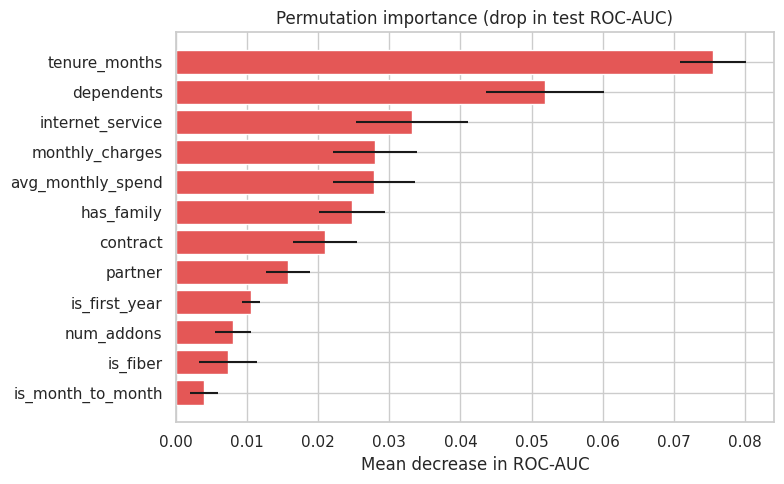

In [14]:
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std})
imp = imp.sort_values("importance", ascending=False).reset_index(drop=True)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#E45756")
ax.set_title("Permutation importance (drop in test ROC-AUC)")
ax.set_xlabel("Mean decrease in ROC-AUC")
plt.tight_layout()
plt.savefig(IMG + "14_feature_importance.png", dpi=130, bbox_inches="tight")
imp.head(12).round(4)

In [15]:
# direction of the effect, for the logistic regression
if final_name == "Logistic Regression":
    names = final_model.named_steps["prep"].get_feature_names_out()
    coefs = pd.Series(final_model.named_steps["model"].coef_[0], index=names).sort_values()
    coefs = coefs[coefs != 0]
    print("Pushes churn DOWN:")
    print(coefs.head(8).round(3).to_string())
    print()
    print("Pushes churn UP:")
    print(coefs.tail(8).iloc[::-1].round(3).to_string())

Pushes churn DOWN:
cat__dependents_Yes         -1.258
cat__contract_Two year      -0.800
num__tenure_months          -0.788
cat__internet_service_DSL   -0.650
cat__partner_Yes            -0.607
num__monthly_charges        -0.597
num__avg_monthly_spend      -0.591
cat__paperless_billing_No   -0.387

Pushes churn UP:
flag__has_family                     1.185
cat__dependents_No                   0.805
flag__is_fiber                       0.559
cat__internet_service_Fiber optic    0.559
flag__is_first_year                  0.538
num__num_addons                      0.404
flag__is_month_to_month              0.396
cat__contract_Month-to-month         0.396


The coefficients should be read as a group, not one by one. Several features overlap (`has_family` is built from `partner` and `dependents`, `is_fiber` repeats `internet_service`), so the weight is shared between them and individual signs can look odd. The permutation importance above is the more reliable view: tenure, family status, internet service, charges and contract matter most, which matches the EDA.

## Save model and metrics

In [16]:
joblib.dump({"pipeline": final_model, "threshold": THRESHOLD, "model_name": final_name,
             "features": list(X_train.columns)}, "../models/churn_model.joblib")

metrics = {
    "selected_model": final_name,
    "decision_threshold": THRESHOLD,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "cv_roc_auc": {"logistic_regression_tuned": float(lr_search.best_score_),
                   "gradient_boosting_tuned": float(gb_search.best_score_)},
    "test_metrics_default_threshold": {k: float(v) for k, v in report(y_test, proba, 0.5).items()},
    "test_metrics_tuned_threshold": {k: float(v) for k, v in report(y_test, proba, THRESHOLD).items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
}
with open("../models/model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

pd.concat([baseline.add_prefix("cv_")], axis=1).to_csv("../models/cv_model_comparison.csv")
imp.to_csv("../models/feature_importance.csv", index=False)
print(json.dumps(metrics["test_metrics_tuned_threshold"], indent=2))

{
  "threshold": 0.33,
  "roc_auc": 0.8511043943269005,
  "pr_auc": 0.6408614290800483,
  "accuracy": 0.6898509581263307,
  "precision": 0.4578313253012048,
  "recall": 0.9144385026737968,
  "f1": 0.6101694915254238
}
